# MPC — TBR

Grafici offline dei risultati in `mpc_multimetric_th/results/tbr`. La metrica interna è `time_eggert`. Nessuna simulazione o propagazione HJ viene rilanciata. I contorni richiedono `brt/time_eggert.npz`.

In [1]:
from pathlib import Path
import sys
import importlib

NOTEBOOK_DIR = Path.cwd()
if not (NOTEBOOK_DIR / "mpc_utils.py").is_file():
    if (NOTEBOOK_DIR / "grafici/mpc_utils.py").is_file():
        NOTEBOOK_DIR = NOTEBOOK_DIR / "grafici"
    else:
        raise FileNotFoundError("Apri il notebook dalla cartella grafici del repository mpc.")
if str(NOTEBOOK_DIR) not in sys.path:
    sys.path.insert(0, str(NOTEBOOK_DIR))

import matplotlib.pyplot as plt
from IPython.display import display
import mpc_utils
importlib.reload(mpc_utils)
from plot_utils import set_style
from mpc_utils import (
    repository_root, load_run, run_manifest, plot_trajectory, plot_frames,
    plot_commands, plot_values, plot_hj_limits, plot_command_planes, export_collection,
)

set_style()
ROOT = repository_root(NOTEBOOK_DIR)
EXPORT = True
FORMATS = ("pdf",)
RUN_NAME = "tbr"
OUTPUT_GROUP = "tbr"
FRAME_TIMES = (5.52, 7.96, 10.40)
FRAME_NCOLS = 1
VIEW_BEHIND = 10.0
VIEW_AHEAD = 25.0
BRT_DIR = ROOT / "brt"
BRT_METRICS = None  # Tutte; ["time_eggert"] per TBR; [] per nessun contorno.
BRT_SMOOTHING = 0.5  # Sigma in celle della griglia x/y originale; 0 disattiva.
BRT_GRID = (241, 161)
HJ_STAGE = 0
HJ_SOFTENED = False
PLANE_TIMES = (5.52, 7.96, 10.40)

figures = {}

def show(name, fig):
    figures[name] = fig
    display(fig)
    plt.close(fig)


## Dati

In [2]:
run = load_run(RUN_NAME, ROOT)
display(run_manifest([run]))


,run,metrics,duration_s,dt_s,steps,predictions,costs,recorded_timers
0,tbr,time_eggert,20.0,0.02,1000,True,True,solve_time


## Traiettoria

Colore associato al tempo; stessa strada delle altre traiettorie singole.

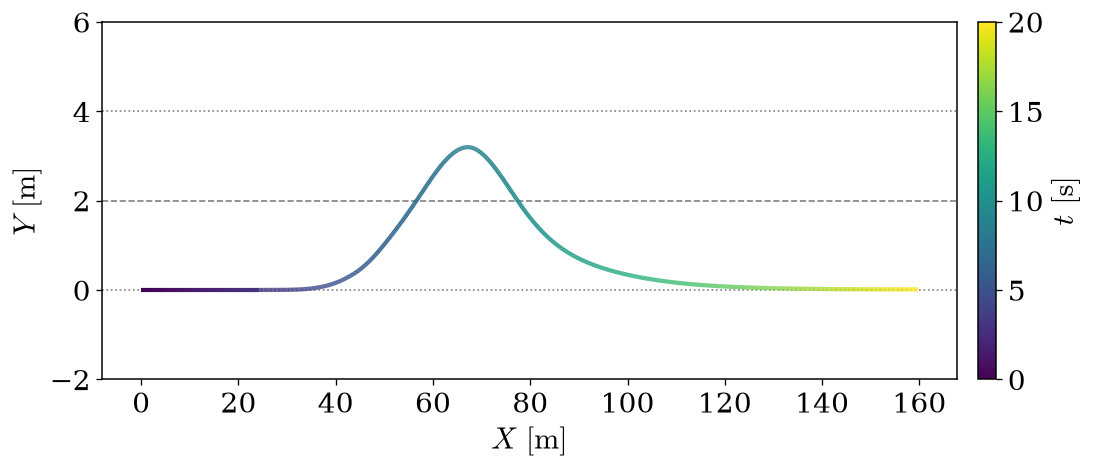

In [3]:
show("tbr_trajectory", plot_trajectory(run))


## Frame

Contorno BRT solo a HJ attivo. Human in secondo piano, traiettoria passata continua e predizione tratteggiata. La legenda è sopra i frame.

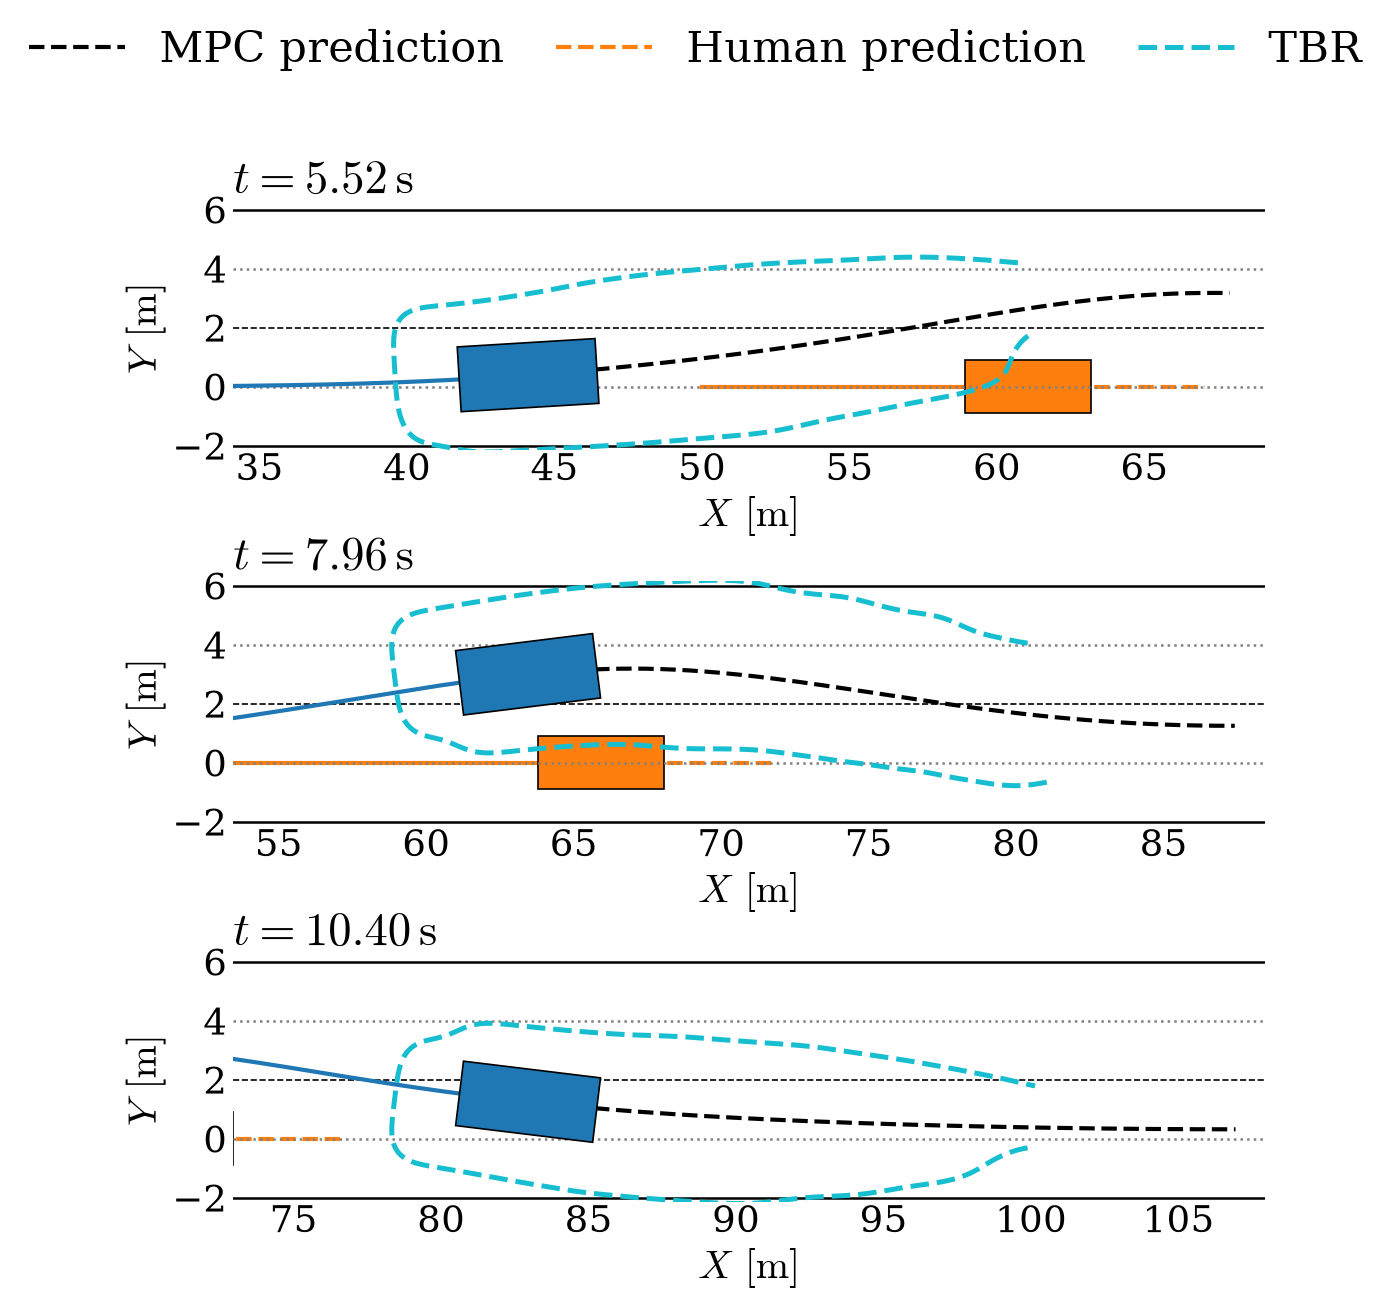

In [4]:
show("tbr_frames", plot_frames(
    run, FRAME_TIMES, behind=VIEW_BEHIND, ahead=VIEW_AHEAD,
    ncols=FRAME_NCOLS, brt_metrics=BRT_METRICS,
    brt_smoothing=BRT_SMOOTHING, brt_grid=BRT_GRID, brt_dir=BRT_DIR,
))


## Comandi

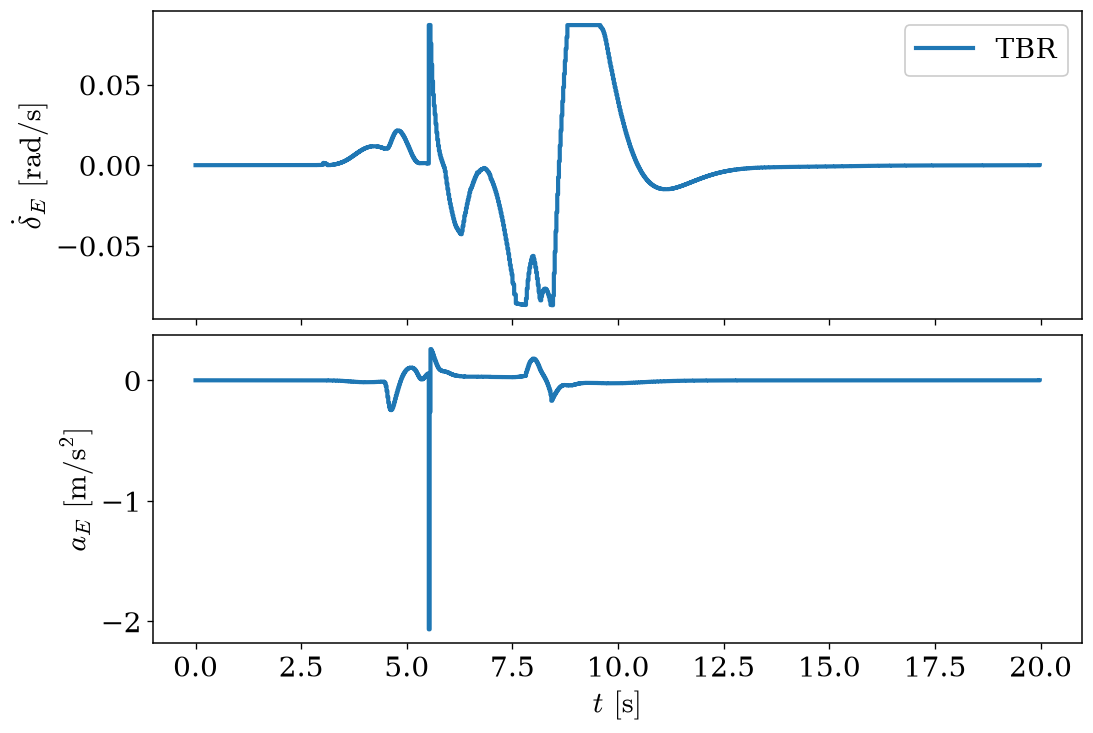

In [5]:
show("tbr_commands", plot_commands(run))


## Value function

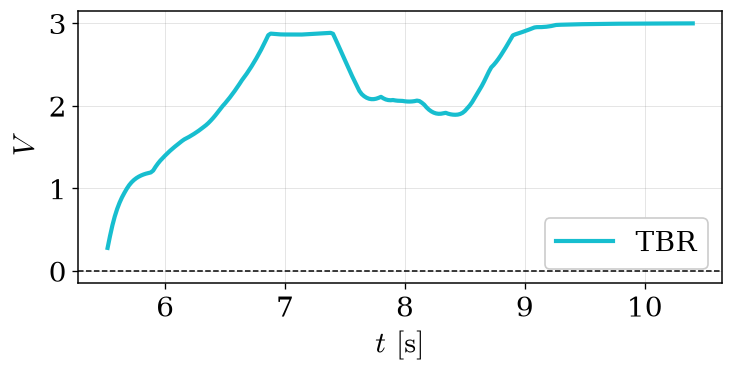

In [6]:
show("tbr_values", plot_values(run))


## Limiti HJ

HJ ON/OFF indicano la prima accensione e lo spegnimento finale allo stage selezionato. I tick y si modificano nel blocco `if axis == 0` di `plot_hj_limits()` in `mpc_utils.py`.

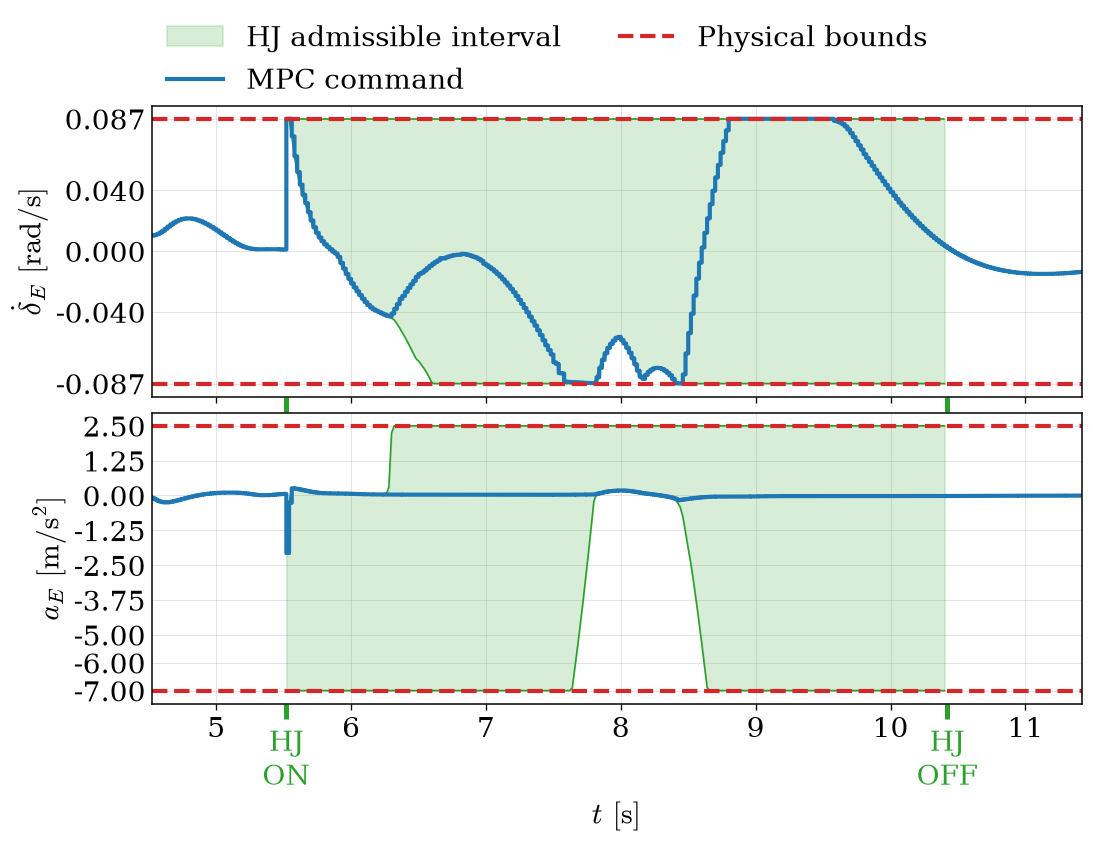

In [7]:
show("tbr_hj_limits", plot_hj_limits(
    run, stage=HJ_STAGE, softened=HJ_SOFTENED,
))


## Command planes

Istanti originali: 5.52, 7.96 e 10.40 s. Lo zoom resta quello dei limiti fisici; lo zoom allargato si usa solo per il confronto multi_time.

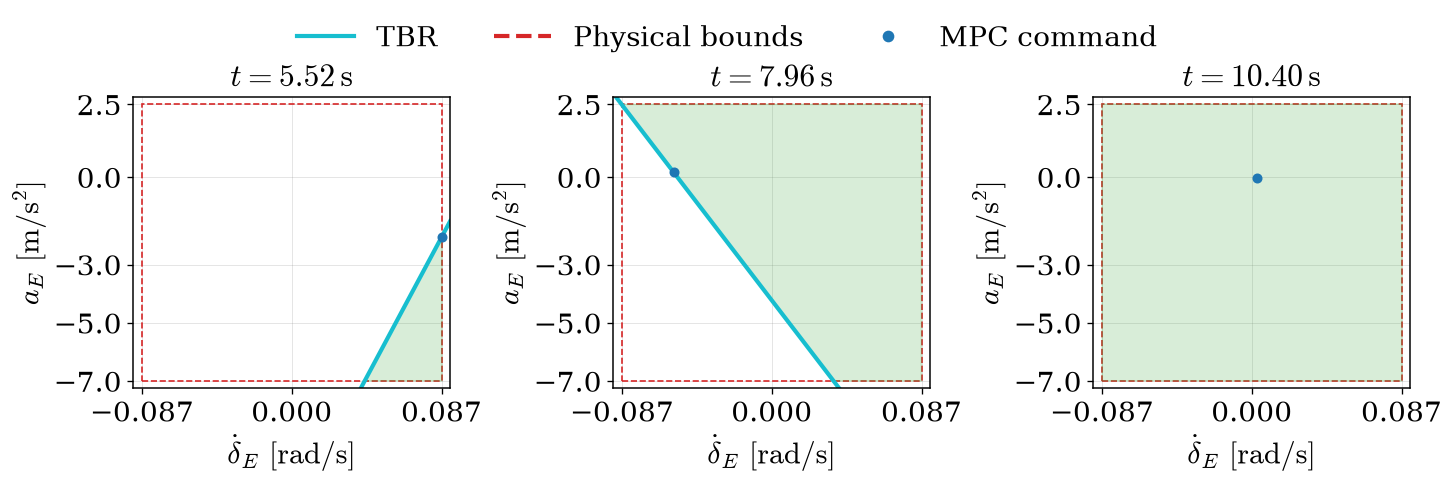

In [8]:
show("tbr_command_planes", plot_command_planes(
    run, times=PLANE_TIMES, stage=HJ_STAGE, softened=HJ_SOFTENED,
))


## Esportazione

In [9]:
if EXPORT:
    exported = export_collection(figures, OUTPUT_GROUP, formats=FORMATS)
    print(f"Esportati {len(exported)} file in grafici/output/{OUTPUT_GROUP}")


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


Salvato: /home/alessio-grisorio/TESI/mpc/grafici/output/tbr/tbr_trajectory.pdf
Salvato: /home/alessio-grisorio/TESI/mpc/grafici/output/tbr/tbr_frames.pdf


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


Salvato: /home/alessio-grisorio/TESI/mpc/grafici/output/tbr/tbr_commands.pdf
Salvato: /home/alessio-grisorio/TESI/mpc/grafici/output/tbr/tbr_values.pdf
Salvato: /home/alessio-grisorio/TESI/mpc/grafici/output/tbr/tbr_hj_limits.pdf


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


Salvato: /home/alessio-grisorio/TESI/mpc/grafici/output/tbr/tbr_command_planes.pdf
Esportati 6 file in grafici/output/tbr
